# Accessing NOAA/NSIDC Sea Ice Concentration CDR V6 via STAC GeoParquet

This notebook demonstrates how to discover and access the NOAA/NSIDC Climate Data Record of Passive Microwave Sea Ice Concentration, Version 6 (G02202) using STAC GeoParquet.

Instead of crawling a STAC API, we load a GeoParquet file containing all STAC items directly. This approach is fast, works offline once the file is downloaded, and requires no special client beyond `pyarrow`.

## Setup

Activate conda environment.

In [3]:
import io
from datetime import datetime, timezone

import fsspec
import matplotlib.pyplot as plt
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.parquet as pq
import pystac
import requests
import stac_geoparquet.arrow as stac_geoparquet
import xarray as xr

In [14]:
collection_url = "https://noaadata.apps.nsidc.org/NOAA/G02202_V6/stac/sea-ice-concentration/collection.json"
collection = pystac.Collection.from_file(collection_url)

print(collection.title)
print(collection.description)
print("Temporal extent:", collection.extent.temporal.intervals)
print("Assets:", list(collection.assets.keys()))

Sea Ice Concentration CDR
The Sea Ice Concentration Climate Data Record (CDR) provides a consistent daily and monthly time series of sea ice concentrations for both the north and south Polar Regions on a 25 km x 25 km grid. These data can be used to estimate how much of the ocean surface is covered by ice, and monitor changes in sea ice concentration. The CDR combines concentration estimates using two algorithms developed at the NASA Goddard Space Flight Center (GSFC). Gridded brightness temperatures acquired from Defense Meteorological Satellite Program (DMSP) passive microwave radiometers, and, beginning 1 January 2025, the JAXA AMSR2 sensor, provide the necessary input to produce the dataset.
Temporal extent: [[datetime.datetime(1978, 10, 25, 0, 0, tzinfo=tzutc()), datetime.datetime(2026, 8, 6, 0, 0, tzinfo=tzutc())]]
Assets: ['daily-items-geoparquet', 'monthly-items-geoparquet']


## Load the STAC Items GeoParquet

Two GeoParquet files are available — one for daily items and one for monthly.
Each row is one STAC item (one file, one hemisphere, one day or month).

In [6]:
STAC_BASE = "https://noaadata.apps.nsidc.org/NOAA/G02202_V6/stac/sea-ice-concentration/"

def read_parquet_from_url(url):
    response = requests.get(url)
    response.raise_for_status()
    return pq.read_table(io.BytesIO(response.content))

daily_table = read_parquet_from_url(f"{STAC_BASE}/sea-ice-concentration-daily-items.parquet")
monthly_table = read_parquet_from_url(f"{STAC_BASE}/sea-ice-concentration-monthly-items.parquet")

print(f"Daily items:   {len(daily_table):,}")
print(f"Monthly items: {len(monthly_table):,}")

Daily items:   17,754
Monthly items: 1,146


## Filter Items

Use PyArrow compute functions to filter by date, hemisphere, or any other property.
This is fast even for the full archive because it operates on columnar data in memory.

In [7]:
start = datetime(2025, 1, 1, tzinfo=timezone.utc)
end = datetime(2025, 1, 31, 23, 59, 59, tzinfo=timezone.utc)

mask = pc.and_(
    pc.and_(
        pc.greater_equal(daily_table["start_datetime"], pa.scalar(start)),
        pc.less_equal(daily_table["start_datetime"], pa.scalar(end)),
    ),
    pc.equal(daily_table["noaa_cdr:hemisphere"], "north"),
)
filtered = daily_table.filter(mask)
print(f"Found {len(filtered)} items")

Found 31 items


## Convert Filtered Rows Back to STAC Items

Use `stac_geoparquet` to convert filtered rows back into STAC item dicts,
then extract asset URLs for data access.

In [8]:
items = list(stac_geoparquet.stac_table_to_items(filtered))

# Look at the first item
item = items[0]
print("Item ID:", item["id"])
print("Start:", item["properties"]["start_datetime"])
print("Hemisphere:", item["properties"]["noaa_cdr:hemisphere"])
print("\nAssets:")
for key, asset in item["assets"].items():
    print(f"  {key}: {asset['href']}")

Item ID: sic_psn25_20250101_am2_v06r00
Start: 2025-01-01T00:00:00.000000Z
Hemisphere: north

Assets:
  netcdf: https://noaadata.apps.nsidc.org/NOAA/G02202_V6/north/daily/2025/sic_psn25_20250101_am2_v06r00.nc


## Open a NetCDF File Directly

Get the NetCDF URL from the item's assets and open it in-place with `fsspec` + `xarray`.
No download required.

In [9]:
netcdf_url = item["assets"]["netcdf"]["href"]
print("Opening:", netcdf_url)

fs = fsspec.filesystem("https")
ds = xr.open_dataset(fs.open(netcdf_url), engine="h5netcdf")
ds

Opening: https://noaadata.apps.nsidc.org/NOAA/G02202_V6/north/daily/2025/sic_psn25_20250101_am2_v06r00.nc


<xarray.Dataset> Size: 2MB
Dimensions:                               (time: 1, y: 448, x: 304)
Coordinates:
  * time                                  (time) datetime64[ns] 8B 2025-01-01
  * y                                     (y) float64 4kB 5.838e+06 ... -5.33...
  * x                                     (x) float64 2kB -3.838e+06 ... 3.73...
Data variables:
    crs                                   int32 4B ...
    cdr_seaice_conc_interp_spatial_flag   (time, y, x) uint8 136kB ...
    cdr_seaice_conc_qa_flag               (time, y, x) uint8 136kB ...
    cdr_seaice_conc_interp_temporal_flag  (time, y, x) uint8 136kB ...
    cdr_seaice_conc                       (time, y, x) float64 1MB ...
    cdr_seaice_conc_stdev                 (time, y, x) float32 545kB ...
Attributes: (12/46)
    Conventions:               CF-1.11, ACDD-1.3
    date_created:              2025-09-30T22:13:45Z
    time_coverage_start:       2025-01-01T00:00:00Z
    time_coverage_end:         2025-01-01T23:59:59Z
    time_coverage_duration:    P1D
    time_coverage_resolution:  P1D
    ...                        ...
    geospatial_lat_min:        30.980564
    geospatial_lat_max:        90.0
    geospatial_lon_min:        -180.0
    geospatial_lon_max:        180.0
    geospatial_lat_units:      degrees_north
    geospatial_lon_units:      degrees_east

## Extract Sea Ice Concentration

The primary variable is `cdr_seaice_conc`. Values are scaled (multiply by `scale_factor` to get fractional concentration 0–1). The `surface_type_mask` variable (in the `cdr_supplementary` group) identifies ocean, land, coast, lake, and pole hole pixels.

In [10]:
sic = ds["cdr_seaice_conc"]
print(sic)
print("\nScale factor:", sic.attrs.get("scale_factor"))
print("Units:", sic.attrs.get("units"))

<xarray.DataArray 'cdr_seaice_conc' (time: 1, y: 448, x: 304)> Size: 1MB
[136192 values with dtype=float64]
Coordinates:
  * time     (time) datetime64[ns] 8B 2025-01-01
  * y        (y) float64 4kB 5.838e+06 5.812e+06 ... -5.312e+06 -5.338e+06
  * x        (x) float64 2kB -3.838e+06 -3.812e+06 ... 3.712e+06 3.738e+06
Attributes:
    standard_name:          sea_ice_area_fraction
    coverage_content_type:  image
    units:                  1
    long_name:              NOAA/NSIDC CDR of Passive Microwave Sea Ice Conce...
    grid_mapping:           crs
    ancillary_variables:    cdr_seaice_conc_stdev cdr_seaice_conc_qa_flag
    valid_range:            [  0 100]

Scale factor: None
Units: 1


## Quick Plot

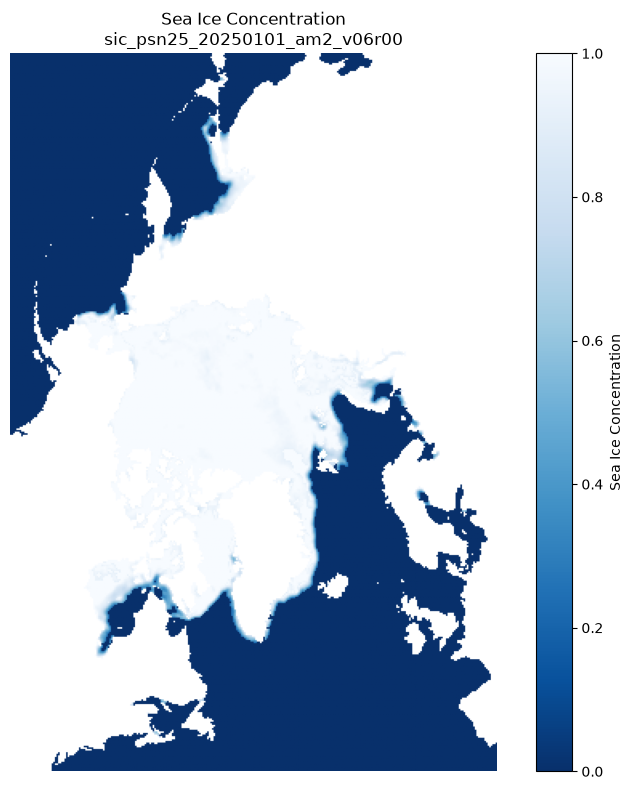

In [11]:
sic = ds["cdr_seaice_conc"]
conc = sic.values.squeeze() * sic.attrs.get("scale_factor", 1.0)

fig, ax = plt.subplots(figsize=(8, 8))
im = ax.imshow(conc, cmap="Blues_r", vmin=0, vmax=1, origin="upper")
plt.colorbar(im, ax=ax, label="Sea Ice Concentration")
ax.set_title(f"Sea Ice Concentration\n{item['id']}")
ax.axis("off")
plt.tight_layout()
plt.show()

## Working with Monthly Data

The same pattern works for monthly items. Monthly files contain `cdr_seaice_conc_monthly` as the primary variable.

In [12]:
start_monthly = datetime(2023, 1, 1, tzinfo=timezone.utc)
end_monthly = datetime(2023, 12, 31, 23, 59, 59, tzinfo=timezone.utc)

mask_monthly = pc.and_(
    pc.and_(
        pc.greater_equal(monthly_table["start_datetime"], pa.scalar(start_monthly)),
        pc.less_equal(monthly_table["start_datetime"], pa.scalar(end_monthly)),
    ),
    pc.equal(monthly_table["noaa_cdr:hemisphere"], "south"),
)
monthly_filtered = monthly_table.filter(mask_monthly)
monthly_items = list(stac_geoparquet.stac_table_to_items(monthly_filtered))
print(f"Found {len(monthly_items)} monthly items")

monthly_url = monthly_items[0]["assets"]["netcdf"]["href"]
ds_monthly = xr.open_dataset(fs.open(monthly_url), engine="h5netcdf")
print(ds_monthly["cdr_seaice_conc_monthly"])

Found 12 monthly items
<xarray.DataArray 'cdr_seaice_conc_monthly' (time: 1, y: 332, x: 316)> Size: 420kB
[104912 values with dtype=float32]
Coordinates:
  * time     (time) datetime64[ns] 8B 2023-01-01
  * y        (y) float64 3kB 4.338e+06 4.312e+06 ... -3.912e+06 -3.938e+06
  * x        (x) float64 3kB -3.938e+06 -3.912e+06 ... 3.912e+06 3.938e+06
Attributes:
    long_name:              NOAA/NSIDC CDR of Passive Microwave Monthly North...
    standard_name:          sea_ice_area_fraction
    coverage_content_type:  image
    units:                  1
    valid_range:            [  0 100]
    grid_mapping:           crs


## Software License

Copyright 2026 NOAA NCAI. Licensed under the MIT License.